# Stage 7 – Model Optimization and Final Model Selection

This notebook optimizes the strongest baseline models identified during Stage 6.

The baseline experiments identified Random Forest and XGBoost as the strongest candidate models according to Macro F1-score.

Random Forest achieved the highest baseline Macro F1-score but showed substantial overfitting. In addition, the baseline classification report showed weak recall for the minority `functional needs repair` class.

To keep model optimization computationally efficient, a controlled manual search strategy is used instead of an exhaustive hyperparameter search.

Candidate configurations will first be evaluated using a stratified validation subset created from the training data.

The strongest configurations will then be confirmed using cross-validation before final model selection.

The independent test dataset will remain untouched until the final model has been selected.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Stage 7 libraries imported successfully.")

Stage 7 libraries imported successfully.


## 2. Load Prepared Modelling Data and Saved Artifacts

The training and testing datasets prepared during Stage 4 are loaded together with the saved preprocessing transformer and target label encoder.

The training dataset will be used for optimization.

The independent test dataset will remain untouched until the final model has been selected.

In [2]:
train_data = pd.read_csv("../data/processed/train_model_data.csv")
test_data = pd.read_csv("../data/processed/test_model_data.csv")

X_train_model = train_data.drop(columns=["status_group"])
y_train_model = train_data["status_group"]

X_test_model = test_data.drop(columns=["status_group"])
y_test_model = test_data["status_group"]

saved_preprocessor = joblib.load("../models/preprocessor.joblib")
label_encoder = joblib.load("../models/label_encoder.joblib")

y_train_encoded = label_encoder.transform(y_train_model)
y_test_encoded = label_encoder.transform(y_test_model)

print("Training predictors:", X_train_model.shape)
print("Training target    :", y_train_encoded.shape)

print("Testing predictors :", X_test_model.shape)
print("Testing target     :", y_test_encoded.shape)

print("\nTarget classes:")

for i, class_name in enumerate(label_encoder.classes_):
    print(f"{i} -> {class_name}")

Training predictors: (47520, 18)
Training target    : (47520,)
Testing predictors : (11880, 18)
Testing target     : (11880,)

Target classes:
0 -> functional
1 -> functional needs repair
2 -> non functional


## 3. Create an Optimization and Validation Split

To make hyperparameter experimentation computationally efficient, the original training dataset is further divided into an optimization subset and a validation subset.

An 80:20 stratified split is used so that the three target classes maintain approximately the same proportions in both subsets.

The optimization subset will be used to train candidate model configurations, while the validation subset will be used to compare their performance.

The independent test dataset remains untouched and will only be used after the final model has been selected.

In [3]:
X_opt, X_val, y_opt, y_val = train_test_split(
    X_train_model,
    y_train_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_train_encoded
)

print("Optimization predictors:", X_opt.shape)
print("Optimization target    :", y_opt.shape)

print("Validation predictors  :", X_val.shape)
print("Validation target      :", y_val.shape)

print("\nClass distribution (%)")

print("\nOptimization:")
print(
    pd.Series(y_opt)
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nValidation:")
print(
    pd.Series(y_val)
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Optimization predictors: (38016, 18)
Optimization target    : (38016,)
Validation predictors  : (9504, 18)
Validation target      : (9504,)

Class distribution (%)

Optimization:
0    54.31
1     7.27
2    38.42
Name: proportion, dtype: float64

Validation:
0    54.30
1     7.27
2    38.43
Name: proportion, dtype: float64


## 4. Random Forest Validation Baseline

Before testing optimized Random Forest configurations, the original baseline Random Forest is trained using the optimization subset and evaluated on the validation subset.

This provides a reference performance level for the faster optimization process.

The preprocessing transformer is cloned and fitted using only the optimization subset so that the validation data does not influence preprocessing parameters.

The main comparison metrics are:

- Macro F1-score
- Recall for `functional needs repair`
- F1-score for `functional needs repair`
- Accuracy

In [4]:
baseline_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

baseline_rf_pipeline.fit(
    X_opt,
    y_opt
)

baseline_rf_predictions = baseline_rf_pipeline.predict(
    X_val
)

baseline_rf_accuracy = accuracy_score(
    y_val,
    baseline_rf_predictions
)

baseline_rf_macro_f1 = f1_score(
    y_val,
    baseline_rf_predictions,
    average="macro"
)

baseline_rf_report = classification_report(
    y_val,
    baseline_rf_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

repair_class_name = "functional needs repair"

baseline_rf_repair_recall = (
    baseline_rf_report[repair_class_name]["recall"]
)

baseline_rf_repair_f1 = (
    baseline_rf_report[repair_class_name]["f1-score"]
)

print("Baseline Random Forest Validation Results")
print("-----------------------------------------")

print(
    "Accuracy:",
    round(baseline_rf_accuracy, 4)
)

print(
    "Macro F1:",
    round(baseline_rf_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(baseline_rf_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(baseline_rf_repair_f1, 4)
)

Baseline Random Forest Validation Results
-----------------------------------------
Accuracy: 0.7926
Macro F1: 0.6755
Repair-class Recall: 0.3343
Repair-class F1: 0.3969


### 4.1 Random Forest with Class Weighting

The baseline Random Forest showed weak recall for the minority `functional needs repair` class.

To investigate whether class imbalance is contributing to this problem, a second Random Forest is trained using `class_weight="balanced_subsample"`.

This automatically gives greater importance to less frequent classes during tree construction while retaining the same baseline Random Forest configuration.

Only the class-weighting strategy is changed so that its effect can be compared directly with the baseline model.

In [5]:
balanced_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

balanced_rf_pipeline.fit(
    X_opt,
    y_opt
)

balanced_rf_predictions = balanced_rf_pipeline.predict(
    X_val
)

balanced_rf_accuracy = accuracy_score(
    y_val,
    balanced_rf_predictions
)

balanced_rf_macro_f1 = f1_score(
    y_val,
    balanced_rf_predictions,
    average="macro"
)

balanced_rf_report = classification_report(
    y_val,
    balanced_rf_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

balanced_rf_repair_recall = (
    balanced_rf_report["functional needs repair"]["recall"]
)

balanced_rf_repair_f1 = (
    balanced_rf_report["functional needs repair"]["f1-score"]
)

print("Balanced Random Forest Validation Results")
print("-----------------------------------------")

print("Accuracy:",
      round(balanced_rf_accuracy, 4))

print("Macro F1:",
      round(balanced_rf_macro_f1, 4))

print("Repair-class Recall:",
      round(balanced_rf_repair_recall, 4))

print("Repair-class F1:",
      round(balanced_rf_repair_f1, 4))

Balanced Random Forest Validation Results
-----------------------------------------
Accuracy: 0.7936
Macro F1: 0.6817
Repair-class Recall: 0.3618
Repair-class F1: 0.4136


### 4.2 Control Random Forest Tree Depth

Class weighting improved Macro F1-score and minority-class performance, so `class_weight="balanced_subsample"` is retained.

The baseline Random Forest previously showed a large difference between training and validation performance, indicating overfitting.

To reduce model complexity, the maximum depth of each tree is limited to 20.

Only tree depth is changed in this experiment so that its effect can be directly compared with the previous balanced Random Forest.

In [6]:
balanced_depth_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

balanced_depth_rf_pipeline.fit(
    X_opt,
    y_opt
)

balanced_depth_rf_predictions = (
    balanced_depth_rf_pipeline.predict(X_val)
)

balanced_depth_rf_accuracy = accuracy_score(
    y_val,
    balanced_depth_rf_predictions
)

balanced_depth_rf_macro_f1 = f1_score(
    y_val,
    balanced_depth_rf_predictions,
    average="macro"
)

balanced_depth_rf_report = classification_report(
    y_val,
    balanced_depth_rf_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

balanced_depth_rf_repair_recall = (
    balanced_depth_rf_report[
        "functional needs repair"
    ]["recall"]
)

balanced_depth_rf_repair_f1 = (
    balanced_depth_rf_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Balanced + Depth-Limited Random Forest")
print("--------------------------------------")

print(
    "Accuracy:",
    round(balanced_depth_rf_accuracy, 4)
)

print(
    "Macro F1:",
    round(balanced_depth_rf_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(balanced_depth_rf_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(balanced_depth_rf_repair_f1, 4)
)

Balanced + Depth-Limited Random Forest
--------------------------------------
Accuracy: 0.7803
Macro F1: 0.677
Repair-class Recall: 0.4486
Repair-class F1: 0.4139


### 4.3 Increase the Minimum Samples per Leaf

Limiting the maximum tree depth substantially improved recall for the minority `functional needs repair` class, but slightly reduced overall Macro F1-score and accuracy.

A less restrictive regularisation strategy is therefore tested by setting `min_samples_leaf=2`.

This prevents trees from creating leaves based on individual training observations while still allowing deeper tree structures.

Class weighting is retained because it previously improved both Macro F1-score and minority-class performance.

In [7]:
balanced_leaf_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

balanced_leaf_rf_pipeline.fit(
    X_opt,
    y_opt
)

balanced_leaf_rf_predictions = (
    balanced_leaf_rf_pipeline.predict(X_val)
)

balanced_leaf_rf_accuracy = accuracy_score(
    y_val,
    balanced_leaf_rf_predictions
)

balanced_leaf_rf_macro_f1 = f1_score(
    y_val,
    balanced_leaf_rf_predictions,
    average="macro"
)

balanced_leaf_rf_report = classification_report(
    y_val,
    balanced_leaf_rf_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

balanced_leaf_rf_repair_recall = (
    balanced_leaf_rf_report[
        "functional needs repair"
    ]["recall"]
)

balanced_leaf_rf_repair_f1 = (
    balanced_leaf_rf_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Balanced RF + min_samples_leaf=2")
print("--------------------------------")

print(
    "Accuracy:",
    round(balanced_leaf_rf_accuracy, 4)
)

print(
    "Macro F1:",
    round(balanced_leaf_rf_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(balanced_leaf_rf_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(balanced_leaf_rf_repair_f1, 4)
)

Balanced RF + min_samples_leaf=2
--------------------------------
Accuracy: 0.7716
Macro F1: 0.6762
Repair-class Recall: 0.508
Repair-class F1: 0.4231


### 4.4 Test a Less Restrictive Maximum Tree Depth

Limiting tree depth to 20 improved minority-class recall but reduced overall Macro F1-score and accuracy.

A maximum depth of 25 is therefore tested as a less restrictive alternative.

The objective is to determine whether a slightly deeper Random Forest can maintain improved detection of the `functional needs repair` class while recovering some of the overall predictive performance.

Class weighting remains enabled because it previously improved the baseline model.

In [8]:
balanced_depth25_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=25,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

balanced_depth25_rf_pipeline.fit(
    X_opt,
    y_opt
)

balanced_depth25_rf_predictions = (
    balanced_depth25_rf_pipeline.predict(X_val)
)

balanced_depth25_rf_accuracy = accuracy_score(
    y_val,
    balanced_depth25_rf_predictions
)

balanced_depth25_rf_macro_f1 = f1_score(
    y_val,
    balanced_depth25_rf_predictions,
    average="macro"
)

balanced_depth25_rf_report = classification_report(
    y_val,
    balanced_depth25_rf_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

balanced_depth25_rf_repair_recall = (
    balanced_depth25_rf_report[
        "functional needs repair"
    ]["recall"]
)

balanced_depth25_rf_repair_f1 = (
    balanced_depth25_rf_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Balanced RF + max_depth=25")
print("--------------------------")

print(
    "Accuracy:",
    round(balanced_depth25_rf_accuracy, 4)
)

print(
    "Macro F1:",
    round(balanced_depth25_rf_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(balanced_depth25_rf_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(balanced_depth25_rf_repair_f1, 4)
)

Balanced RF + max_depth=25
--------------------------
Accuracy: 0.7934
Macro F1: 0.6851
Repair-class Recall: 0.3922
Repair-class F1: 0.4218


### 4.5 Check Overfitting of the Best Random Forest Configuration

The `max_depth=25` Random Forest achieved the strongest validation Macro F1-score among the tested Random Forest configurations.

Its training and validation Macro F1-scores are compared to determine whether restricting tree depth also reduced the substantial overfitting observed in the original baseline Random Forest.

In [9]:
rf_depth25_train_predictions = (
    balanced_depth25_rf_pipeline.predict(X_opt)
)

rf_depth25_train_macro_f1 = f1_score(
    y_opt,
    rf_depth25_train_predictions,
    average="macro"
)

rf_depth25_f1_gap = (
    rf_depth25_train_macro_f1
    - balanced_depth25_rf_macro_f1
)

print("Best Tuned Random Forest – Overfitting Check")
print("--------------------------------------------")

print(
    "Training Macro F1:",
    round(rf_depth25_train_macro_f1, 4)
)

print(
    "Validation Macro F1:",
    round(balanced_depth25_rf_macro_f1, 4)
)

print(
    "Train-Validation Gap:",
    round(rf_depth25_f1_gap, 4)
)

Best Tuned Random Forest – Overfitting Check
--------------------------------------------
Training Macro F1: 0.9739
Validation Macro F1: 0.6851
Train-Validation Gap: 0.2888


## 5. XGBoost Optimization

### 5.1 XGBoost Validation Baseline

Before modifying XGBoost hyperparameters, the Stage 6 baseline configuration is trained using the optimization subset and evaluated on the validation subset.

This provides a direct reference for later XGBoost tuning experiments.

The same evaluation criteria are used as for Random Forest:

- Accuracy
- Macro F1-score
- Recall for `functional needs repair`
- F1-score for `functional needs repair`

In [10]:
baseline_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

baseline_xgb_pipeline.fit(
    X_opt,
    y_opt
)

baseline_xgb_predictions = (
    baseline_xgb_pipeline.predict(X_val)
)

baseline_xgb_accuracy = accuracy_score(
    y_val,
    baseline_xgb_predictions
)

baseline_xgb_macro_f1 = f1_score(
    y_val,
    baseline_xgb_predictions,
    average="macro"
)

baseline_xgb_report = classification_report(
    y_val,
    baseline_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

baseline_xgb_repair_recall = (
    baseline_xgb_report[
        "functional needs repair"
    ]["recall"]
)

baseline_xgb_repair_f1 = (
    baseline_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Baseline XGBoost Validation Results")
print("-----------------------------------")

print(
    "Accuracy:",
    round(baseline_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(baseline_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(baseline_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(baseline_xgb_repair_f1, 4)
)

Baseline XGBoost Validation Results
-----------------------------------
Accuracy: 0.7948
Macro F1: 0.6648
Repair-class Recall: 0.2692
Repair-class F1: 0.3676


### 5.2 XGBoost with Balanced Sample Weights

The baseline XGBoost model achieved strong overall accuracy but relatively weak performance for the minority `functional needs repair` class.

To address this class imbalance, balanced sample weights are applied during model training.

Minority-class observations receive greater importance while majority-class observations receive lower relative importance.

The XGBoost hyperparameters remain unchanged so that the effect of class weighting can be evaluated independently.

In [11]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_opt
)

print("Sample weight summary:")
print(pd.Series(xgb_sample_weights).describe())

Sample weight summary:
count    38016.000000
mean         1.000000
std          1.011221
min          0.613775
25%          0.613775
50%          0.613775
75%          0.867529
max          4.586319
dtype: float64


In [12]:
balanced_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

balanced_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=xgb_sample_weights
)

balanced_xgb_predictions = (
    balanced_xgb_pipeline.predict(X_val)
)

balanced_xgb_accuracy = accuracy_score(
    y_val,
    balanced_xgb_predictions
)

balanced_xgb_macro_f1 = f1_score(
    y_val,
    balanced_xgb_predictions,
    average="macro"
)

balanced_xgb_report = classification_report(
    y_val,
    balanced_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

balanced_xgb_repair_recall = (
    balanced_xgb_report[
        "functional needs repair"
    ]["recall"]
)

balanced_xgb_repair_f1 = (
    balanced_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Balanced XGBoost Validation Results")
print("-----------------------------------")

print(
    "Accuracy:",
    round(balanced_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(balanced_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(balanced_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(balanced_xgb_repair_f1, 4)
)

Balanced XGBoost Validation Results
-----------------------------------
Accuracy: 0.7481
Macro F1: 0.663
Repair-class Recall: 0.6179
Repair-class F1: 0.4118


### 5.3 XGBoost with Moderate Class Weighting

Full balanced sample weighting substantially increased recall for the minority `functional needs repair` class, but reduced overall accuracy and did not improve Macro F1-score.

This suggests that the weighting was too aggressive.

A moderate weighting strategy is therefore tested by applying the square root of the balanced sample weights.

This continues to give greater importance to minority-class observations while reducing the impact on the two larger classes.

All other XGBoost parameters remain unchanged so that the effect of moderate class weighting can be evaluated independently.

In [13]:
moderate_xgb_weights = np.sqrt(
    compute_sample_weight(
        class_weight="balanced",
        y=y_opt
    )
)

print("Moderate sample weight summary:")
print(
    pd.Series(moderate_xgb_weights)
    .describe()
)

Moderate sample weight summary:
count    38016.000000
mean         0.939004
std          0.343912
min          0.783438
25%          0.783438
50%          0.783438
75%          0.931413
max          2.141569
dtype: float64


In [14]:
moderate_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

moderate_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=moderate_xgb_weights
)

moderate_xgb_predictions = (
    moderate_xgb_pipeline.predict(X_val)
)

moderate_xgb_accuracy = accuracy_score(
    y_val,
    moderate_xgb_predictions
)

moderate_xgb_macro_f1 = f1_score(
    y_val,
    moderate_xgb_predictions,
    average="macro"
)

moderate_xgb_report = classification_report(
    y_val,
    moderate_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

moderate_xgb_repair_recall = (
    moderate_xgb_report[
        "functional needs repair"
    ]["recall"]
)

moderate_xgb_repair_f1 = (
    moderate_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Moderately Weighted XGBoost Results")
print("-----------------------------------")

print(
    "Accuracy:",
    round(moderate_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(moderate_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(moderate_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(moderate_xgb_repair_f1, 4)
)

Moderately Weighted XGBoost Results
-----------------------------------
Accuracy: 0.7789
Macro F1: 0.6787
Repair-class Recall: 0.4616
Repair-class F1: 0.4236


### 5.4 Check Overfitting of the Moderately Weighted XGBoost

The moderately weighted XGBoost improved minority-class recall and achieved competitive Macro F1 performance.

Training and validation Macro F1-scores are compared to determine whether the model is overfitting the optimization subset.

This information will guide the next XGBoost tuning decision.

In [15]:
moderate_xgb_train_predictions = (
    moderate_xgb_pipeline.predict(X_opt)
)

moderate_xgb_train_macro_f1 = f1_score(
    y_opt,
    moderate_xgb_train_predictions,
    average="macro"
)

moderate_xgb_f1_gap = (
    moderate_xgb_train_macro_f1
    - moderate_xgb_macro_f1
)

print("Moderately Weighted XGBoost – Overfitting Check")
print("-----------------------------------------------")

print(
    "Training Macro F1:",
    round(moderate_xgb_train_macro_f1, 4)
)

print(
    "Validation Macro F1:",
    round(moderate_xgb_macro_f1, 4)
)

print(
    "Train-Validation Gap:",
    round(moderate_xgb_f1_gap, 4)
)

Moderately Weighted XGBoost – Overfitting Check
-----------------------------------------------
Training Macro F1: 0.8264
Validation Macro F1: 0.6787
Train-Validation Gap: 0.1477


### 5.5 Reduce XGBoost Tree Depth

The moderately weighted XGBoost achieved competitive validation performance but still showed a noticeable difference between training and validation Macro F1-scores.

To reduce model complexity and improve generalisation, the maximum depth of each boosted tree is limited to 4.

All other model settings, including the moderate sample-weighting strategy, remain unchanged so that the effect of tree depth can be evaluated independently.

In [16]:
moderate_depth4_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                max_depth=4,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

moderate_depth4_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=moderate_xgb_weights
)

moderate_depth4_xgb_predictions = (
    moderate_depth4_xgb_pipeline.predict(X_val)
)

moderate_depth4_xgb_accuracy = accuracy_score(
    y_val,
    moderate_depth4_xgb_predictions
)

moderate_depth4_xgb_macro_f1 = f1_score(
    y_val,
    moderate_depth4_xgb_predictions,
    average="macro"
)

moderate_depth4_xgb_report = classification_report(
    y_val,
    moderate_depth4_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

moderate_depth4_xgb_repair_recall = (
    moderate_depth4_xgb_report[
        "functional needs repair"
    ]["recall"]
)

moderate_depth4_xgb_repair_f1 = (
    moderate_depth4_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Moderate XGBoost + max_depth=4")
print("-------------------------------")

print(
    "Accuracy:",
    round(moderate_depth4_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(moderate_depth4_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(moderate_depth4_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(moderate_depth4_xgb_repair_f1, 4)
)

Moderate XGBoost + max_depth=4
-------------------------------
Accuracy: 0.773
Macro F1: 0.6727
Repair-class Recall: 0.4486
Repair-class F1: 0.4232


### 5.6 Reduce the XGBoost Learning Rate

Reducing the maximum tree depth did not improve validation performance.

The previous moderately weighted XGBoost configuration is therefore retained as the reference model.

A lower learning rate of 0.1 is now tested. A smaller learning rate makes each boosting step more conservative and may improve generalisation by reducing overly aggressive corrections during sequential tree construction.

All other settings are kept unchanged so that the effect of the learning rate can be evaluated independently.

In [17]:
moderate_lr_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                learning_rate=0.1,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

moderate_lr_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=moderate_xgb_weights
)

moderate_lr_xgb_predictions = (
    moderate_lr_xgb_pipeline.predict(X_val)
)

moderate_lr_xgb_accuracy = accuracy_score(
    y_val,
    moderate_lr_xgb_predictions
)

moderate_lr_xgb_macro_f1 = f1_score(
    y_val,
    moderate_lr_xgb_predictions,
    average="macro"
)

moderate_lr_xgb_report = classification_report(
    y_val,
    moderate_lr_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

moderate_lr_xgb_repair_recall = (
    moderate_lr_xgb_report[
        "functional needs repair"
    ]["recall"]
)

moderate_lr_xgb_repair_f1 = (
    moderate_lr_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Moderate XGBoost + learning_rate=0.1")
print("------------------------------------")

print(
    "Accuracy:",
    round(moderate_lr_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(moderate_lr_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(moderate_lr_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(moderate_lr_xgb_repair_f1, 4)
)

Moderate XGBoost + learning_rate=0.1
------------------------------------
Accuracy: 0.7715
Macro F1: 0.6678
Repair-class Recall: 0.4284
Repair-class F1: 0.4117


### 5.7 Apply Row Subsampling to XGBoost

Reducing the learning rate did not improve validation performance, so the previous moderately weighted XGBoost configuration remains the best XGBoost candidate.

To further investigate generalisation, a subsampling rate of 0.8 is tested.

With `subsample=0.8`, each boosting tree is trained using a randomly selected 80% of the available training observations. This can reduce overfitting by introducing additional variation between trees.

All other model settings remain unchanged so that the effect of row subsampling can be evaluated independently.

In [18]:
moderate_subsample_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                subsample=0.8,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

moderate_subsample_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=moderate_xgb_weights
)

moderate_subsample_xgb_predictions = (
    moderate_subsample_xgb_pipeline.predict(X_val)
)

moderate_subsample_xgb_accuracy = accuracy_score(
    y_val,
    moderate_subsample_xgb_predictions
)

moderate_subsample_xgb_macro_f1 = f1_score(
    y_val,
    moderate_subsample_xgb_predictions,
    average="macro"
)

moderate_subsample_xgb_report = classification_report(
    y_val,
    moderate_subsample_xgb_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

moderate_subsample_xgb_repair_recall = (
    moderate_subsample_xgb_report[
        "functional needs repair"
    ]["recall"]
)

moderate_subsample_xgb_repair_f1 = (
    moderate_subsample_xgb_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Moderate XGBoost + subsample=0.8")
print("--------------------------------")

print(
    "Accuracy:",
    round(moderate_subsample_xgb_accuracy, 4)
)

print(
    "Macro F1:",
    round(moderate_subsample_xgb_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(moderate_subsample_xgb_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(moderate_subsample_xgb_repair_f1, 4)
)

Moderate XGBoost + subsample=0.8
--------------------------------
Accuracy: 0.7806
Macro F1: 0.6811
Repair-class Recall: 0.4602
Repair-class F1: 0.4291


### 5.8 Check Overfitting of the Best XGBoost Configuration

Applying `subsample=0.8` improved validation Macro F1-score and minority-class F1-score.

Training and validation Macro F1-scores are now compared to determine whether row subsampling also reduced the overfitting observed in the previous XGBoost configuration.

In [19]:
subsample_xgb_train_predictions = (
    moderate_subsample_xgb_pipeline.predict(X_opt)
)

subsample_xgb_train_macro_f1 = f1_score(
    y_opt,
    subsample_xgb_train_predictions,
    average="macro"
)

subsample_xgb_f1_gap = (
    subsample_xgb_train_macro_f1
    - moderate_subsample_xgb_macro_f1
)

print("Best XGBoost – Overfitting Check")
print("--------------------------------")

print(
    "Training Macro F1:",
    round(subsample_xgb_train_macro_f1, 4)
)

print(
    "Validation Macro F1:",
    round(moderate_subsample_xgb_macro_f1, 4)
)

print(
    "Train-Validation Gap:",
    round(subsample_xgb_f1_gap, 4)
)

Best XGBoost – Overfitting Check
--------------------------------
Training Macro F1: 0.8391
Validation Macro F1: 0.6811
Train-Validation Gap: 0.1579


### 5.9 Apply Feature Subsampling to XGBoost

The `subsample=0.8` configuration improved validation performance but the model still showed a noticeable training-validation gap.

A feature-subsampling rate of 0.8 is therefore tested using `colsample_bytree=0.8`.

This allows each boosted tree to use a randomly selected subset of the available features, which may reduce overfitting and improve generalisation.

The moderate class-weighting strategy and row subsampling are retained because they produced the strongest XGBoost validation results so far.

In [20]:
moderate_subsample_colsample_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

moderate_subsample_colsample_xgb_pipeline.fit(
    X_opt,
    y_opt,
    classifier__sample_weight=moderate_xgb_weights
)

xgb_final_predictions = (
    moderate_subsample_colsample_xgb_pipeline.predict(X_val)
)

xgb_final_accuracy = accuracy_score(
    y_val,
    xgb_final_predictions
)

xgb_final_macro_f1 = f1_score(
    y_val,
    xgb_final_predictions,
    average="macro"
)

xgb_final_report = classification_report(
    y_val,
    xgb_final_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

xgb_final_repair_recall = (
    xgb_final_report[
        "functional needs repair"
    ]["recall"]
)

xgb_final_repair_f1 = (
    xgb_final_report[
        "functional needs repair"
    ]["f1-score"]
)

print("Moderate XGBoost + Row & Feature Subsampling")
print("--------------------------------------------")

print(
    "Accuracy:",
    round(xgb_final_accuracy, 4)
)

print(
    "Macro F1:",
    round(xgb_final_macro_f1, 4)
)

print(
    "Repair-class Recall:",
    round(xgb_final_repair_recall, 4)
)

print(
    "Repair-class F1:",
    round(xgb_final_repair_f1, 4)
)

Moderate XGBoost + Row & Feature Subsampling
--------------------------------------------
Accuracy: 0.7806
Macro F1: 0.6829
Repair-class Recall: 0.466
Repair-class F1: 0.4351


### 5.10 Check Overfitting of the Best XGBoost Configuration

The combination of moderate class weighting, row subsampling, and feature subsampling produced the strongest XGBoost validation performance.

Training and validation Macro F1-scores are compared to determine whether the final XGBoost configuration also improves model generalisation.

In [21]:
final_xgb_train_predictions = (
    moderate_subsample_colsample_xgb_pipeline.predict(X_opt)
)

final_xgb_train_macro_f1 = f1_score(
    y_opt,
    final_xgb_train_predictions,
    average="macro"
)

final_xgb_f1_gap = (
    final_xgb_train_macro_f1
    - xgb_final_macro_f1
)

print("Final Tuned XGBoost – Overfitting Check")
print("---------------------------------------")

print(
    "Training Macro F1:",
    round(final_xgb_train_macro_f1, 4)
)

print(
    "Validation Macro F1:",
    round(xgb_final_macro_f1, 4)
)

print(
    "Train-Validation Gap:",
    round(final_xgb_f1_gap, 4)
)

Final Tuned XGBoost – Overfitting Check
---------------------------------------
Training Macro F1: 0.8301
Validation Macro F1: 0.6829
Train-Validation Gap: 0.1471


## 6. Cross-Validation Confirmation of Optimized Models

### 6.1 Tuned Random Forest Cross-Validation

The strongest Random Forest configuration identified during optimization is now evaluated using 5-fold Stratified K-Fold cross-validation on the complete training dataset.

This provides a more reliable estimate of its generalisation performance than the single optimization-validation split.

The independent test dataset remains untouched.

In [22]:
tuned_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=25,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

confirmation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_confirmation = cross_validate(
    tuned_rf_pipeline,
    X_train_model,
    y_train_encoded,
    cv=confirmation_cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "f1_weighted": "f1_weighted",
        "recall_macro": "recall_macro"
    },
    return_train_score=True,
    n_jobs=1
)

print("Tuned Random Forest – 5-Fold CV")
print("--------------------------------")

print(
    "Mean Accuracy:",
    round(rf_confirmation["test_accuracy"].mean(), 4)
)

print(
    "Mean Macro F1:",
    round(rf_confirmation["test_f1_macro"].mean(), 4)
)

print(
    "Macro F1 Std:",
    round(rf_confirmation["test_f1_macro"].std(), 4)
)

print(
    "Mean Weighted F1:",
    round(rf_confirmation["test_f1_weighted"].mean(), 4)
)

print(
    "Mean Macro Recall:",
    round(rf_confirmation["test_recall_macro"].mean(), 4)
)

print(
    "Mean Train Macro F1:",
    round(rf_confirmation["train_f1_macro"].mean(), 4)
)

Tuned Random Forest – 5-Fold CV
--------------------------------
Mean Accuracy: 0.7926
Mean Macro F1: 0.6836
Macro F1 Std: 0.0065
Mean Weighted F1: 0.7896
Mean Macro Recall: 0.6728
Mean Train Macro F1: 0.9734


### 6.2 Tuned XGBoost Cross-Validation

The strongest XGBoost configuration is evaluated using the same 5-fold Stratified K-Fold cross-validation strategy.

The optimized XGBoost uses:

- moderate class weighting,
- `subsample=0.8`,
- `colsample_bytree=0.8`,
- 200 boosting trees.

Sample weights are calculated independently within each training fold so that class-weight information is derived only from the corresponding training portion.

The results will be compared with the tuned Random Forest before final model selection.

In [23]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    confirmation_cv.split(
        X_train_model,
        y_train_encoded
    ),
    start=1
):

    X_fold_train = X_train_model.iloc[train_idx]
    X_fold_val = X_train_model.iloc[val_idx]

    y_fold_train = y_train_encoded[train_idx]
    y_fold_val = y_train_encoded[val_idx]

    # Moderate class weighting
    fold_weights = np.sqrt(
        compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )
    )

    fold_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(saved_preprocessor)
            ),
            (
                "classifier",
                XGBClassifier(
                    objective="multi:softprob",
                    eval_metric="mlogloss",
                    n_estimators=200,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=42,
                    n_jobs=-1,
                    tree_method="hist"
                )
            )
        ]
    )

    fold_pipeline.fit(
        X_fold_train,
        y_fold_train,
        classifier__sample_weight=fold_weights
    )

    train_predictions = fold_pipeline.predict(
        X_fold_train
    )

    val_predictions = fold_pipeline.predict(
        X_fold_val
    )

    fold_result = {
        "fold": fold,

        "accuracy": accuracy_score(
            y_fold_val,
            val_predictions
        ),

        "macro_f1": f1_score(
            y_fold_val,
            val_predictions,
            average="macro"
        ),

        "weighted_f1": f1_score(
            y_fold_val,
            val_predictions,
            average="weighted"
        ),

        "macro_recall": recall_score(
            y_fold_val,
            val_predictions,
            average="macro"
        ),

        "train_macro_f1": f1_score(
            y_fold_train,
            train_predictions,
            average="macro"
        )
    }

    xgb_cv_results.append(fold_result)

    print(
        f"Fold {fold} completed - "
        f"Macro F1: {fold_result['macro_f1']:.4f}"
    )

Fold 1 completed - Macro F1: 0.6926
Fold 2 completed - Macro F1: 0.6833
Fold 3 completed - Macro F1: 0.6915
Fold 4 completed - Macro F1: 0.6790
Fold 5 completed - Macro F1: 0.6810


In [24]:
xgb_cv_df = pd.DataFrame(
    xgb_cv_results
)

print("\nTuned XGBoost – 5-Fold CV")
print("--------------------------")

print(
    "Mean Accuracy:",
    round(xgb_cv_df["accuracy"].mean(), 4)
)

print(
    "Mean Macro F1:",
    round(xgb_cv_df["macro_f1"].mean(), 4)
)

print(
    "Macro F1 Std:",
    round(xgb_cv_df["macro_f1"].std(ddof=0), 4)
)

print(
    "Mean Weighted F1:",
    round(xgb_cv_df["weighted_f1"].mean(), 4)
)

print(
    "Mean Macro Recall:",
    round(xgb_cv_df["macro_recall"].mean(), 4)
)

print(
    "Mean Train Macro F1:",
    round(xgb_cv_df["train_macro_f1"].mean(), 4)
)


Tuned XGBoost – 5-Fold CV
--------------------------
Mean Accuracy: 0.7826
Mean Macro F1: 0.6855
Macro F1 Std: 0.0055
Mean Weighted F1: 0.7838
Mean Macro Recall: 0.6896
Mean Train Macro F1: 0.8296


## 7. Comparison of Optimized Candidate Models

The tuned Random Forest and tuned XGBoost models are compared using 5-fold Stratified K-Fold cross-validation.

Macro F1-score remains the primary selection metric because all three waterpoint-status classes should contribute equally to model selection.

Generalisation behaviour and Macro Recall are also considered because the project places importance on identifying the minority `functional needs repair` class.

In [25]:
optimized_model_comparison = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],

    "Mean Accuracy": [
        rf_confirmation["test_accuracy"].mean(),
        xgb_cv_df["accuracy"].mean()
    ],

    "Mean Macro F1": [
        rf_confirmation["test_f1_macro"].mean(),
        xgb_cv_df["macro_f1"].mean()
    ],

    "Macro F1 Std": [
        rf_confirmation["test_f1_macro"].std(),
        xgb_cv_df["macro_f1"].std(ddof=0)
    ],

    "Mean Weighted F1": [
        rf_confirmation["test_f1_weighted"].mean(),
        xgb_cv_df["weighted_f1"].mean()
    ],

    "Mean Macro Recall": [
        rf_confirmation["test_recall_macro"].mean(),
        xgb_cv_df["macro_recall"].mean()
    ],

    "Mean Train Macro F1": [
        rf_confirmation["train_f1_macro"].mean(),
        xgb_cv_df["train_macro_f1"].mean()
    ]
})

optimized_model_comparison["Train-CV F1 Gap"] = (
    optimized_model_comparison["Mean Train Macro F1"]
    - optimized_model_comparison["Mean Macro F1"]
)

display(
    optimized_model_comparison.round(4)
)

,Model,Mean Accuracy,Mean Macro F1,Macro F1 Std,Mean Weighted F1,Mean Macro Recall,Mean Train Macro F1,Train-CV F1 Gap
0,Tuned Random Forest,0.7926,0.6836,0.0065,0.7896,0.6728,0.9734,0.2898
1,Tuned XGBoost,0.7826,0.6855,0.0055,0.7838,0.6896,0.8296,0.1441


### 7.1 Final Candidate Model Selection

Based on the 5-fold cross-validation comparison, **Tuned XGBoost is selected as the final model candidate**.

Although the tuned Random Forest achieved a slightly higher mean accuracy of 0.7926 compared with 0.7826 for XGBoost, accuracy was not the primary model-selection metric because the target classes are imbalanced.

Tuned XGBoost achieved the higher mean Macro F1-score of 0.6855 compared with 0.6836 for Random Forest. It also achieved a higher mean Macro Recall of 0.6896, indicating better balanced detection across the three target classes.

The XGBoost model also demonstrated substantially better generalisation. Its training-to-cross-validation Macro F1 gap was 0.1441, compared with 0.2898 for Random Forest. This indicates that the optimized Random Forest continued to overfit the training data considerably more strongly.

XGBoost also showed slightly lower variation across cross-validation folds, with a Macro F1 standard deviation of 0.0055 compared with 0.0065 for Random Forest.

Therefore, Tuned XGBoost provides the best overall balance between:

- Macro F1 performance,
- class-balanced recall,
- cross-validation stability,
- minority-class sensitivity,
- and generalisation to unseen data.

The independent test dataset has not yet been used. It will now be used once to obtain the final unbiased performance estimate of the selected XGBoost model.

## 8. Train the Selected Final Model

The tuned XGBoost configuration selected through cross-validation is retrained using the complete training dataset.

The final configuration uses:

- 200 boosting trees,
- moderate class weighting,
- `subsample=0.8`,
- `colsample_bytree=0.8`,
- histogram-based tree construction.

Moderate sample weights are recalculated using the complete training target so that minority-class observations receive additional importance without using the aggressive full-balancing strategy.

The independent test dataset is not used during model fitting.

In [26]:
# Calculate moderate class weights using the complete training dataset
final_train_weights = np.sqrt(
    compute_sample_weight(
        class_weight="balanced",
        y=y_train_encoded
    )
)

# Build final XGBoost pipeline
final_xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(saved_preprocessor)
        ),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                eval_metric="mlogloss",
                n_estimators=200,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

# Fit using the complete training dataset
final_xgb_pipeline.fit(
    X_train_model,
    y_train_encoded,
    classifier__sample_weight=final_train_weights
)

print("Final tuned XGBoost trained successfully.")
print("Training observations:", X_train_model.shape[0])
print("Input features:", X_train_model.shape[1])

Final tuned XGBoost trained successfully.
Training observations: 47520
Input features: 18


## 9. Final Evaluation on the Independent Test Set

The selected and fully trained XGBoost model is evaluated once using the independent test dataset.

This test dataset was excluded from:

- preprocessing parameter estimation,
- baseline model selection,
- hyperparameter experimentation,
- class-weight selection,
- cross-validation,
- final candidate selection.

Therefore, the test-set results provide an independent estimate of how the final model is expected to perform on previously unseen waterpoint records.

The primary metric remains Macro F1-score, while accuracy, Weighted F1, and Macro Recall are also reported.

In [27]:
final_test_predictions = final_xgb_pipeline.predict(
    X_test_model
)

final_test_accuracy = accuracy_score(
    y_test_encoded,
    final_test_predictions
)

final_test_macro_f1 = f1_score(
    y_test_encoded,
    final_test_predictions,
    average="macro"
)

final_test_weighted_f1 = f1_score(
    y_test_encoded,
    final_test_predictions,
    average="weighted"
)

final_test_macro_recall = recall_score(
    y_test_encoded,
    final_test_predictions,
    average="macro"
)

print("Final XGBoost – Independent Test Results")
print("----------------------------------------")

print(
    "Accuracy:",
    round(final_test_accuracy, 4)
)

print(
    "Macro F1:",
    round(final_test_macro_f1, 4)
)

print(
    "Weighted F1:",
    round(final_test_weighted_f1, 4)
)

print(
    "Macro Recall:",
    round(final_test_macro_recall, 4)
)

Final XGBoost – Independent Test Results
----------------------------------------
Accuracy: 0.7863
Macro F1: 0.6926
Weighted F1: 0.7888
Macro Recall: 0.7023


### 9.1 Final Class-Level Performance

The final model is evaluated separately for each waterpoint-status class using precision, recall, and F1-score.

Particular attention is given to the `functional needs repair` class because this was the least represented class and showed the weakest performance during baseline model development.

These results are used to determine whether the optimized model improved minority-class detection on unseen data.

In [28]:
final_test_report = classification_report(
    y_test_encoded,
    final_test_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print(final_test_report)

                         precision    recall  f1-score   support

             functional     0.8175    0.8379    0.8276      6452
functional needs repair     0.4124    0.5017    0.4527       863
         non functional     0.8304    0.7671    0.7975      4565

               accuracy                         0.7863     11880
              macro avg     0.6868    0.7023    0.6926     11880
           weighted avg     0.7930    0.7863    0.7888     11880



###  Interpretation of Final Class-Level Performance

The final XGBoost model achieved strong performance for the two larger target classes and substantially improved detection of the minority `functional needs repair` class.

For the `functional` class, the model achieved a precision of 0.8175, recall of 0.8379, and F1-score of 0.8276. This indicates that the model identifies operational waterpoints reliably.

For the `non functional` class, the model achieved a precision of 0.8304, recall of 0.7671, and F1-score of 0.7975, showing similarly strong predictive performance for completely failed waterpoints.

The `functional needs repair` class remained the most difficult class to predict. However, the optimized model achieved a recall of 0.5017 and an F1-score of 0.4527 on the independent test set.

This means that the final model correctly identifies approximately 50% of previously unseen waterpoints that require repair. This represents a substantial improvement over the baseline Random Forest, which showed considerably weaker minority-class recall during Stage 6.

The final test-set Macro F1-score of 0.6926 and Macro Recall of 0.7023 indicate that the optimized XGBoost model provides a more balanced performance across all three operational-status classes.

Although minority-class performance remains lower than for the two larger classes, the optimization process improved the model's ability to identify repair-needed waterpoints while maintaining strong overall predictive performance.

### 9.2 Final Test-Set Confusion Matrix

A confusion matrix is used to examine the final model's prediction errors on the independent test dataset.

Particular attention is given to `functional needs repair` observations to determine whether missed repair cases are more commonly predicted as `functional` or `non functional`.

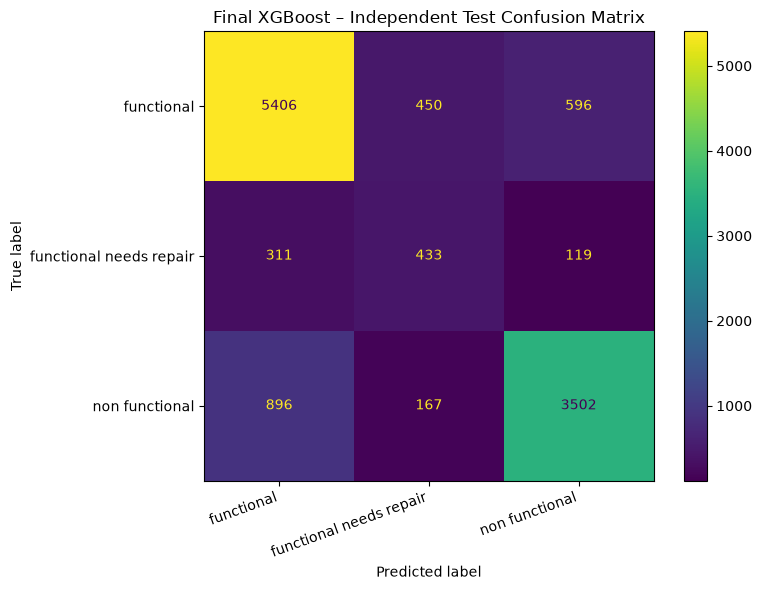

In [29]:
final_cm = confusion_matrix(
    y_test_encoded,
    final_test_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Final XGBoost – Independent Test Confusion Matrix"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()
plt.show()  

### Interpretation of the Final Confusion Matrix

The final test-set confusion matrix shows that the optimized XGBoost model performs strongly for the `functional` and `non functional` classes while providing substantially improved detection of the minority `functional needs repair` class.

For the `functional` class, 5,406 of 6,452 waterpoints were correctly classified. A total of 450 were predicted as `functional needs repair`, while 596 were predicted as `non functional`.

For the `non functional` class, 3,502 of 4,565 waterpoints were correctly identified. A total of 896 were incorrectly predicted as `functional`, while 167 were classified as `functional needs repair`.

The most important improvement is observed for the `functional needs repair` class. Out of 863 actual repair-needed waterpoints, 433 were correctly identified, corresponding to a recall of approximately 50.17%.

Among the missed repair-needed cases, 311 were incorrectly classified as `functional` and 119 were classified as `non functional`.

During baseline model development, the Random Forest identified only approximately 32.46% of the `functional needs repair` observations. The optimized XGBoost therefore increased repair-class recall by approximately 17.7 percentage points.

The number of repair-needed waterpoints incorrectly treated as fully functional remains an important limitation. However, the optimization process substantially reduced this problem and produced a more balanced classifier across all three waterpoint-status categories.

From an operational perspective, the improved repair-class detection is particularly valuable because correctly identifying waterpoints requiring maintenance can support earlier inspection and intervention before complete failure occurs.

## 10. Save and Verify the Final Model

The final tuned XGBoost pipeline is saved for later use in the backend prediction system.

The saved artifact contains both:

- the fitted preprocessing transformer,
- the trained XGBoost classifier.

After saving, the model is reloaded and used to predict the independent test dataset again.

The reloaded predictions are compared with the original final predictions to verify that model serialization has not changed the behaviour of the trained system.

In [30]:
models_dir = Path("../models")
models_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_model_path = (
    models_dir /
    "final_xgboost_model.joblib"
)

joblib.dump(
    final_xgb_pipeline,
    final_model_path
)

print("Final model saved to:")
print(final_model_path)

Final model saved to:
..\models\final_xgboost_model.joblib


In [31]:
loaded_final_model = joblib.load(
    final_model_path
)

reloaded_predictions = loaded_final_model.predict(
    X_test_model
)

predictions_match = np.array_equal(
    final_test_predictions,
    reloaded_predictions
)

print("Reloaded model successfully.")

print(
    "Predictions identical:",
    predictions_match
)

print(
    "Reloaded prediction count:",
    len(reloaded_predictions)
)

Reloaded model successfully.
Predictions identical: True
Reloaded prediction count: 11880


## 11. Save Final Evaluation Results

The final independent test-set performance is saved as experiment evidence.

Both overall evaluation metrics and class-level precision, recall, and F1-score are stored so that the final model results can be reused in the technical report, presentation, and system documentation.

In [32]:
results_dir = Path("../results")
results_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Overall final metrics
final_metrics_df = pd.DataFrame([
    {
        "Model": "Tuned XGBoost",
        "Accuracy": final_test_accuracy,
        "Macro_F1": final_test_macro_f1,
        "Weighted_F1": final_test_weighted_f1,
        "Macro_Recall": final_test_macro_recall
    }
])

final_metrics_path = (
    results_dir /
    "final_model_test_metrics.csv"
)

final_metrics_df.to_csv(
    final_metrics_path,
    index=False
)

# Class-level performance
final_report_dict = classification_report(
    y_test_encoded,
    final_test_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

final_report_df = (
    pd.DataFrame(final_report_dict)
    .transpose()
)

final_report_path = (
    results_dir /
    "final_model_classification_report.csv"
)

final_report_df.to_csv(
    final_report_path
)

print("Final metrics saved to:")
print(final_metrics_path)

print("\nFinal classification report saved to:")
print(final_report_path)

print("\nFinal metrics:")
display(final_metrics_df.round(4))

Final metrics saved to:
..\results\final_model_test_metrics.csv

Final classification report saved to:
..\results\final_model_classification_report.csv

Final metrics:


,Model,Accuracy,Macro_F1,Weighted_F1,Macro_Recall
0,Tuned XGBoost,0.7863,0.6926,0.7888,0.7023


## 12. Stage 7 Summary

The model optimization stage focused on improving the strongest baseline algorithms identified during Stage 6: Random Forest and XGBoost.

The main optimization objective was to improve Macro F1-score while also improving the detection of the minority `functional needs repair` class.

### Random Forest Optimization

The baseline Random Forest achieved strong overall performance but showed substantial overfitting and relatively weak recall for the minority class.

Several controlled experiments were performed, including:

- class weighting,
- maximum tree-depth control,
- minimum samples per leaf.

The strongest Random Forest configuration used:

- `n_estimators=200`
- `max_depth=25`
- `class_weight="balanced_subsample"`

Using 5-fold stratified cross-validation, this model achieved:

- Mean Accuracy: **0.7926**
- Mean Macro F1: **0.6836**
- Mean Weighted F1: **0.7896**
- Mean Macro Recall: **0.6728**
- Macro F1 Standard Deviation: **0.0065**

However, its mean training Macro F1-score was **0.9734**, indicating that considerable overfitting remained.

### XGBoost Optimization

The baseline XGBoost achieved strong accuracy but initially showed weak performance for the `functional needs repair` class.

Several experiments were conducted involving:

- balanced sample weighting,
- moderate sample weighting,
- tree-depth control,
- learning-rate adjustment,
- row subsampling,
- feature subsampling.

The strongest XGBoost configuration used:

- `n_estimators=200`
- moderate class weighting,
- `subsample=0.8`
- `colsample_bytree=0.8`
- histogram-based tree construction.

Using 5-fold stratified cross-validation, the optimized XGBoost achieved:

- Mean Accuracy: **0.7826**
- Mean Macro F1: **0.6855**
- Mean Weighted F1: **0.7838**
- Mean Macro Recall: **0.6896**
- Macro F1 Standard Deviation: **0.0055**
- Mean Training Macro F1: **0.8296**

Although Random Forest achieved slightly higher accuracy, XGBoost achieved the higher Macro F1-score and Macro Recall while showing substantially less overfitting.

Therefore, the optimized **XGBoost model was selected as the final model**.

### Independent Test Performance

After final model selection, the optimized XGBoost pipeline was retrained using the complete training dataset and evaluated once on the previously untouched independent test dataset.

The final test results were:

- Accuracy: **0.7863**
- Macro F1: **0.6926**
- Weighted F1: **0.7888**
- Macro Recall: **0.7023**

The final model achieved the following class-level performance:

- `functional`: F1-score **0.8276**
- `functional needs repair`: F1-score **0.4527**
- `non functional`: F1-score **0.7975**

The recall of the `functional needs repair` class increased to **0.5017**, meaning that the final model correctly identified approximately 50% of previously unseen waterpoints requiring repair.

This represents a substantial improvement over the baseline Random Forest, which achieved a repair-class recall of approximately **0.3246** during Stage 6.

The final XGBoost model therefore provides a better balance between overall predictive performance, minority-class detection, cross-validation stability, and generalisation.

The complete preprocessing and trained XGBoost classifier were saved together as the final reusable prediction pipeline for later backend integration.